# Building a Transferable Adversarial Dataset with MI-FGSM

This notebook creates an **adversarial version of Imagenette** that is designed to **transfer** to models it was *not* crafted on, so it can be used in a separate experiment.

It implements the **Momentum Iterative Fast Gradient Sign Method (MI-FGSM)** from:

> Dong, Liao, Pang, Su, Zhu, Hu, Li. *Boosting Adversarial Attacks with Momentum.* CVPR 2018.

## Why this design gives you transferable examples

Two ideas from the paper are combined:

1. **Momentum (MI-FGSM).** Plain iterative FGSM (I-FGSM) overfits the model it is attacking: the more iterations, the worse it transfers. Accumulating a velocity vector of past gradients stabilises the update direction and helps the attack escape poor local maxima, which keeps transferability high.
2. **Ensemble in logits.** Attacking several models at once (fusing their logits before the loss) finds perturbations that fool *all* of them, and these are more likely to fool other, unseen models too. The paper found logit-fusion works better than fusing predictions or losses.

## Workflow

| Step | What happens |
|---|---|
| 1 | Configure paths and attack hyperparameters |
| 2 | Load an *attack ensemble* (white-box) and *hold-out* models (never attacked, used only to measure transfer) |
| 3 | Read your CSV (`image path, label`) |
| 4 | Run MI-FGSM on every image the ensemble classifies correctly |
| 5 | Save the adversarial images as lossless PNGs plus a metadata CSV |
| 6 | Report white-box and black-box (transfer) fooling rates, and visualise examples |

**Tip:** do a quick test first by setting `MAX_IMAGES = 100` in the config cell, then set it back to `None` for the full run.

## 0. Setup

Uncomment and run the next cell if you need to install dependencies. `torchvision >= 0.13` is required (for the `weights="DEFAULT"` API).

In [1]:
# %pip install torch torchvision pillow pandas matplotlib tqdm

In [2]:
import os
import csv
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.models as models
import torchvision.transforms as T
from torchvision.utils import save_image
from torch.utils.data import Dataset, DataLoader
from PIL import Image

# tqdm gives a progress bar; fall back to a no-op if it isn't installed.
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kwargs):
        return x

# Use the GPU if available. The attack needs many forward/backward passes,
# so a GPU makes a large difference (CPU works but is slow).
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | device: {device}")

torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | device: cuda


/home/geoff/env_torch/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Configuration

Everything you are likely to want to change lives in this one cell.

**Attack hyperparameters (defaults follow the paper):**
- `EPS`: maximum per-pixel change (L-infinity bound) on the 0-255 scale. The paper uses 16. Larger = stronger and more transferable, but more visible.
- `ITERS`: number of MI-FGSM iterations `T`. The step size is `alpha = eps / T`, so the perturbation can just reach the budget.
- `MU`: momentum decay factor. The paper found `1.0` best (it simply sums all past normalised gradients). `0.0` reduces MI-FGSM to plain I-FGSM, which is useful for an ablation.

**Models:**
- `ATTACK_MODELS` are the models the adversarial examples are *crafted against* (the ensemble).
- `HOLDOUT_MODELS` are **never** used during the attack. Their fooling rate is the honest measure of transferability. Pick architectures that differ from the ensemble.

Any classifier name in `torchvision.models` that outputs 1000 ImageNet classes and accepts 224x224 input will work.

In [3]:
# ----------------------------- Data -----------------------------
CSV_PATH   = "imagenette2/imagenette2/noisy_imagenette.csv"        # CSV: column 1 = image path, column 2 = label
IMG_ROOT   = "imagenette2/imagenette2"                  # Prefix for relative paths in the CSV ("" if paths are absolute)
OUT_DIR    = "MI-FGSM"    # Where the adversarial dataset will be written
MAX_IMAGES = None                # e.g. 100 for a quick test run; None = use everything

# --------------------------- Attack settings ---------------------------
EPS        = 32                  # L-inf budget on the 0-255 scale
ITERS      = 15                  # number of iterations T
MU         = 1.0                 # momentum decay factor
BATCH_SIZE = 32                  # lower this if you run out of GPU memory (VGG16 is memory hungry)

# ------------------------------ Models ------------------------------
# Ensemble the attack is crafted against (logits are fused with equal weights).
ATTACK_MODELS  = ["resnet50","vgg16","efficientnet_b0", "mobilenet_v3_large", "densenet121"]
# Held-out models used ONLY to measure transferability. Must not overlap with the above.
HOLDOUT_MODELS = []

# --------------------------- Sanity checks ---------------------------
assert not set(ATTACK_MODELS) & set(HOLDOUT_MODELS), "Hold-out models must differ from attack models"
assert os.path.exists(CSV_PATH), f"CSV not found: {CSV_PATH}"
print("Config OK.")

Config OK.


## 2. Loading models

### Normalisation wrapper
Torchvision models expect inputs normalised with ImageNet mean/std. If we fed them normalised images directly, our epsilon would be measured in "normalised units", which is confusing and different per channel.

Instead, we wrap each model so that it accepts **raw `[0, 1]` pixels** and normalises *inside* the forward pass. This means:
- the attack, the clipping, and `EPS/255` all live in ordinary pixel space,
- the adversarial images we save are exactly what a user would feed in with a plain `ToTensor()`.

We also freeze the model weights (`requires_grad_(False)`). We only need gradients with respect to the **input image**, and freezing the weights saves memory.

In [4]:
class Normalized(nn.Module):
    """Wrap a classifier so it takes [0,1] images and applies ImageNet normalisation internally."""

    def __init__(self, model):
        super().__init__()
        self.model = model
        # register_buffer -> moves with .to(device) but is not a trainable parameter
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        return self.model((x - self.mean) / self.std)


def load_model(name):
    """Load a pretrained torchvision model by name, wrapped, frozen and in eval mode."""
    ctor = getattr(models, name)            # e.g. models.resnet50
    net = ctor(weights="DEFAULT")           # best available pretrained ImageNet weights
    wrapped = Normalized(net).eval().to(device)   # eval(): disables dropout / uses BN running stats
    for p in wrapped.parameters():
        p.requires_grad_(False)             # we only need gradients w.r.t. the input
    return wrapped


print("Loading attack ensemble:", ATTACK_MODELS)
attack_models = {n: load_model(n) for n in ATTACK_MODELS}

print("Loading hold-out models:", HOLDOUT_MODELS)
holdout_models = {n: load_model(n) for n in HOLDOUT_MODELS}

# Convenient combined view for evaluation (attack models first, then hold-outs).
all_models = {**attack_models, **holdout_models}
print(f"Loaded {len(all_models)} models.")

Loading attack ensemble: ['resnet50', 'vgg16', 'efficientnet_b0', 'mobilenet_v3_large', 'densenet121']
Loading hold-out models: []
Loaded 5 models.


## 3. Labels and data loading

### Label mapping
Imagenette is a 10-class subset of ImageNet, but our models predict **1000** ImageNet classes. To check whether a model is right, we map each Imagenette class to its ImageNet-1k index:

| Imagenette class | wnid | ImageNet-1k index |
|---|---|---|
| tench | n01440764 | 0 |
| English springer | n02102040 | 217 |
| cassette player | n02979186 | 482 |
| chain saw | n03000684 | 491 |
| church | n03028079 | 497 |
| French horn | n03394916 | 566 |
| garbage truck | n03417042 | 569 |
| gas pump | n03425413 | 571 |
| golf ball | n03445777 | 574 |
| parachute | n03888257 | 701 |

### CSV parsing
Column 2 of your CSV may contain **wnids**, **class names**, or **integers 0-9**. All are accepted. Integers are assumed to follow the standard Imagenette order (sorted wnids, as in the table above). **If your integers use a different ordering, the labels will be wrong, so verify this.** A header row is detected automatically.

In [5]:
# Imagenette classes in sorted-wnid order (this is the standard Imagenette label order)
WNIDS = ["n01440764", "n02102040", "n02979186", "n03000684", "n03028079",
         "n03394916", "n03417042", "n03425413", "n03445777", "n03888257"]
CLASS_NAMES = ["tench", "english_springer", "cassette_player", "chain_saw", "church",
               "french_horn", "garbage_truck", "gas_pump", "golf_ball", "parachute"]
IMAGENETTE_TO_IN1K = [0, 217, 482, 491, 497, 566, 569, 571, 574, 701]


def _norm(s):
    """Normalise a label string: lower-case, spaces/hyphens -> underscores."""
    return s.strip().lower().replace(" ", "_").replace("-", "_")


# Build a lookup that accepts wnids, class names, or integer strings -> Imagenette index 0..9
LABEL_LOOKUP = {}
for i, (wnid, cname) in enumerate(zip(WNIDS, CLASS_NAMES)):
    LABEL_LOOKUP[wnid] = i
    LABEL_LOOKUP[cname] = i
    LABEL_LOOKUP[str(i)] = i


def parse_label(s):
    """Return the Imagenette index (0-9) for a label string, or None if unrecognised."""
    return LABEL_LOOKUP.get(_norm(s))


def read_csv(path, img_root):
    """Read (image_path, imagenette_label) pairs from the CSV."""
    items = []
    with open(path, newline="") as f:
        for n, row in enumerate(csv.reader(f)):
            if len(row) < 2 or not row[0].strip():
                continue                                  # skip blank / malformed rows
            lab = parse_label(row[1])
            if lab is None:
                if n == 0:
                    continue                              # unrecognised label on row 1 -> it's a header
                raise ValueError(f"Row {n + 1}: unrecognised label {row[1]!r}. "
                                 f"Expected a wnid, class name, or integer 0-9.")
            p = row[0].strip()
            if img_root and not os.path.isabs(p):
                p = os.path.join(img_root, p)             # prepend root for relative paths
            items.append((p, lab))
    if not items:
        raise ValueError("No valid rows found in CSV.")
    return items


items = read_csv(CSV_PATH, IMG_ROOT)
if MAX_IMAGES:
    items = items[:MAX_IMAGES]

# Fail early (before any heavy compute) if image files are missing.
missing = [p for p, _ in items if not os.path.exists(p)]
if missing:
    raise FileNotFoundError(f"{len(missing)} image(s) not found, e.g. {missing[0]}. Check IMG_ROOT.")

counts = pd.Series([CLASS_NAMES[l] for _, l in items]).value_counts()
print(f"Loaded {len(items)} images. Class distribution:\n{counts}")

Loaded 13394 images. Class distribution:
cassette_player     1350
garbage_truck       1350
tench               1350
english_springer    1350
church              1350
parachute           1350
french_horn         1350
golf_ball           1350
gas_pump            1350
chain_saw           1244
Name: count, dtype: int64


### Dataset and DataLoader

Preprocessing matches the standard torchvision ImageNet evaluation pipeline: **resize to 256, center-crop to 224**, convert to a tensor in `[0, 1]`. Note: normalisation is *not* applied here, because the model wrappers do it internally.

The dataset also returns the **index** of each image, so after filtering and batching we can still recover the original filename when saving.

Because the saved adversarial images are 224x224 crops, an experiment that loads them later should **not** resize or crop them again (that would partially destroy the perturbation).

In [6]:
# Resize shorter side to 256, center crop 224x224, convert to float tensor in [0, 1].
preprocess = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor()])


class CSVDataset(Dataset):
    """Loads images listed in the CSV. Returns (image_tensor, imagenette_label, dataset_index)."""

    def __init__(self, items, transform):
        self.items = items
        self.transform = transform

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        path, label = self.items[i]
        img = Image.open(path).convert("RGB")      # force 3 channels (some files are greyscale)
        return self.transform(img), label, i


loader = DataLoader(
    CSVDataset(items, preprocess),
    batch_size=BATCH_SIZE,
    shuffle=False,        # keep order deterministic
    num_workers=2,        # set to 0 if you hit multiprocessing issues (e.g. on Windows)
)

## 4. The MI-FGSM attack

This is Algorithm 1 (single model) and Algorithm 2 (ensemble) from the paper, in one function.

For `T` iterations, starting from `x*_0 = x` and `g_0 = 0`:

1. **Fuse logits** across the ensemble: `l(x) = sum_k w_k * l_k(x)` (Eq. 8). With one model this is just that model's logits.
2. **Loss:** softmax cross-entropy between the fused logits and the true label (Eq. 9). We *maximise* this, pushing the image away from the correct class.
3. **Gradient** of the loss with respect to the current adversarial image.
4. **Normalise** the gradient by its L1 norm (per image). The paper notes gradient magnitudes vary a lot between iterations, so normalising stops large-gradient iterations from dominating the momentum.
5. **Momentum update:** `g_{t+1} = mu * g_t + normalised_grad` (Eq. 6).
6. **Step:** `x*_{t+1} = x*_t + alpha * sign(g_{t+1})` (Eq. 7), with `alpha = eps / T`.
7. **Project** back into the epsilon-ball around the original image and into the valid pixel range `[0, 1]`.

**Implementation note on the L1 norm:** the paper divides by the L1 norm (sum of absolute values). The authors' code uses the *mean* absolute value instead. These differ only by a constant factor (the number of pixels), which does not change `sign(g)`, so both give identical results. We use the mean.

In [7]:
def mi_fgsm(model_list, x, y, eps, iters, mu, weights=None):
    """
    Non-targeted, L-infinity MI-FGSM, optionally against an ensemble (fused in logits).

    Args:
        model_list : list of models mapping [0,1] images -> logits
        x          : clean images, shape (B, 3, H, W), values in [0, 1]
        y          : true labels (ImageNet-1k indices), shape (B,)
        eps        : L-inf budget in [0,1] pixel units (i.e. EPS / 255)
        iters      : number of iterations T
        mu         : momentum decay factor
        weights    : ensemble weights (default: equal); must be >= 0 and sum to 1

    Returns:
        adversarial images, same shape as x, values in [0, 1], ||x_adv - x||_inf <= eps
    """
    if weights is None:
        weights = [1.0 / len(model_list)] * len(model_list)

    alpha = eps / iters                        # step size so T steps can just reach the budget
    g = torch.zeros_like(x)                    # accumulated (momentum) gradient, g_0 = 0
    x_adv = x.clone().detach()                 # x*_0 = x

    for _ in range(iters):
        x_adv.requires_grad_(True)

        # Eq. 8: weighted sum of each model's logits
        logits = sum(w * m(x_adv) for w, m in zip(weights, model_list))
        # Eq. 9: softmax cross-entropy loss on the fused logits (averaged over the batch)
        loss = F.cross_entropy(logits, y)

        # Gradient of the loss w.r.t. the image. Each image's loss only depends on that
        # image, so batching does not mix gradients between images.
        grad = torch.autograd.grad(loss, x_adv)[0]

        # Per-image gradient normalisation (L1 up to a constant). clamp avoids divide-by-zero.
        grad = grad / grad.abs().mean(dim=(1, 2, 3), keepdim=True).clamp_min(1e-12)

        # Eq. 6: momentum accumulation of normalised gradients
        g = mu * g + grad

        # Eq. 7: take a step in the direction of the sign of the accumulated gradient
        x_adv = x_adv.detach() + alpha * g.sign()

        # Project: stay within eps of the original image AND inside valid pixel range [0, 1]
        x_adv = torch.min(torch.max(x_adv, x - eps), x + eps).clamp(0, 1).detach()

    return x_adv

## 5. Generating the dataset

For each batch we:

1. **Filter** to images that *every model in the attack ensemble* classifies correctly. Measuring attack success on images that were already misclassified is meaningless (the paper does the same).
2. **Attack** the remaining images with MI-FGSM against the ensemble.
3. **Quantise** to 8-bit (`round(x*255)/255`). Images are stored as 8-bit PNGs, so we evaluate the *quantised* images, i.e. exactly what ends up on disk. PNG is lossless, so the perturbation is preserved (JPEG would destroy much of it).
4. **Evaluate** every model (attack and hold-out) on the adversarial images.
5. **Save** each image to `OUT_DIR/<class_name>/<filename>.png`.

**Reading the stats later:**
- Fooling rate on *attack-ensemble* models = **white-box** success.
- Fooling rate on *hold-out* models = **transfer / black-box** success. This is the number that tells you how transferable the dataset is.
- For each model, the rate is computed only over images that model classified correctly when clean.

The attack is deterministic (no randomness), so re-running gives the same dataset.

In [8]:
eps = EPS / 255.0                                           # budget in [0,1] pixel units
to_in1k = torch.tensor(IMAGENETTE_TO_IN1K, device=device)   # Imagenette idx -> ImageNet-1k idx

for c in CLASS_NAMES:                                       # one output folder per class
    os.makedirs(os.path.join(OUT_DIR, c), exist_ok=True)

# Running counts per model: how many correctly-classified images got fooled.
stats = {name: {"fooled": 0, "evaluated": 0} for name in all_models}
records = []                                                # one metadata row per saved image
n_seen, n_kept = 0, 0
t0 = time.time()

for x, y10, idx in tqdm(loader, desc="Attacking"):
    x, y10 = x.to(device), y10.to(device)
    y = to_in1k[y10]                                        # true labels as ImageNet-1k indices
    n_seen += len(x)

    # ---- 1. keep only images that ALL attack-ensemble models get right ----
    with torch.no_grad():
        keep = torch.ones(len(x), dtype=torch.bool, device=device)
        for m in attack_models.values():
            keep &= (m(x).argmax(1) == y)
    if keep.sum() == 0:
        continue
    x, y, y10 = x[keep], y[keep], y10[keep]
    idx = idx[keep.cpu()]                                   # indices must be filtered on CPU
    n_kept += len(x)

    # ---- 2. craft adversarial examples against the ensemble ----
    x_adv = mi_fgsm(list(attack_models.values()), x, y, eps=eps, iters=ITERS, mu=MU)

    # ---- 3. quantise to 8-bit so we evaluate exactly what gets saved to disk ----
    x_adv = torch.round(x_adv * 255) / 255

    # ---- 4. evaluate every model on the (quantised) adversarial images ----
    adv_preds, clean_oks = {}, {}
    with torch.no_grad():
        for name, m in all_models.items():
            clean_ok = (m(x).argmax(1) == y)                # was this model right on the clean image?
            adv_pred = m(x_adv).argmax(1)                   # what does it predict now?
            fooled = (adv_pred != y)
            stats[name]["fooled"] += (fooled & clean_ok).sum().item()
            stats[name]["evaluated"] += clean_ok.sum().item()
            adv_preds[name] = adv_pred.cpu()
            clean_oks[name] = clean_ok.cpu()

    # ---- 5. save images + collect metadata ----
    for i in range(len(x)):
        src_path = items[idx[i].item()][0]
        stem = os.path.splitext(os.path.basename(src_path))[0]
        cls = CLASS_NAMES[y10[i].item()]
        rel = os.path.join(cls, stem + ".png")
        if os.path.exists(os.path.join(OUT_DIR, rel)):      # avoid overwriting on duplicate filenames
            rel = os.path.join(cls, f"{stem}_{idx[i].item()}.png")
        save_image(x_adv[i].cpu(), os.path.join(OUT_DIR, rel))   # PNG = lossless

        rec = {
            "file": rel,
            "source_path": src_path,
            "label": y10[i].item(),
            "class": cls,
            "linf_255": round((x_adv[i] - x[i]).abs().max().item() * 255, 1),  # sanity: should be <= EPS
        }
        for name in all_models:
            rec[f"{name}_clean_ok"] = int(clean_oks[name][i].item())
            rec[f"{name}_adv_pred_in1k"] = adv_preds[name][i].item()
        records.append(rec)

elapsed = time.time() - t0
print(f"\nDone in {elapsed / 60:.1f} min. Processed {n_seen} images, attacked {n_kept}.")

Attacking: 100%|███████████████████████████████████████████████████████████████████| 419/419 [8:16:08<00:00, 71.05s/it]


Done in 496.1 min. Processed 13394 images, attacked 10117.


## 6. Save metadata and report results

`metadata.csv` has one row per adversarial image: its filename, original source path, true label, measured L-infinity perturbation, and for every model whether it was correct on the clean image plus its prediction on the adversarial one (ImageNet-1k index). This lets you filter the dataset later (e.g. keep only images that fool a particular model).

The `linf_255` column is a sanity check: every value should be at most `EPS`.

In [9]:
# ---- Save per-image metadata ----
meta = pd.DataFrame(records)
meta_path = os.path.join(OUT_DIR, "metadata.csv")
meta.to_csv(meta_path, index=False)

# ---- Build the results table ----
rows = []
for name, s in stats.items():
    rows.append({
        "model": name,
        "role": "attack ensemble (white-box)" if name in attack_models else "HOLD-OUT (transfer)",
        "fooled": s["fooled"],
        "evaluated": s["evaluated"],
        "fooling_rate_%": round(100 * s["fooled"] / max(s["evaluated"], 1), 1),
    })
results = pd.DataFrame(rows)

print(f"Images in source CSV:             {n_seen}")
print(f"Correct on all attack models:     {n_kept} ({100 * n_kept / max(n_seen, 1):.1f}%)  <- size of adversarial dataset")
print(f"Max measured L-inf perturbation:  {meta['linf_255'].max()} / 255  (budget = {EPS})\n")
display(results) if "display" in globals() else print(results.to_string(index=False))

# Save a summary record of this run so the dataset is reproducible / documented.
summary = {
    "config": {"EPS": EPS, "ITERS": ITERS, "MU": MU, "ATTACK_MODELS": ATTACK_MODELS,
               "HOLDOUT_MODELS": HOLDOUT_MODELS, "preprocess": "Resize(256)+CenterCrop(224)"},
    "n_source_images": n_seen,
    "n_adversarial_images": n_kept,
    "results": rows,
}
with open(os.path.join(OUT_DIR, "summary.json"), "w") as f:
    json.dump(summary, f, indent=2)
print(f"\nSaved: {meta_path}, {os.path.join(OUT_DIR, 'summary.json')}")

Images in source CSV:             13394
Correct on all attack models:     10117 (75.5%)  <- size of adversarial dataset
Max measured L-inf perturbation:  32.0 / 255  (budget = 32)

             model                        role  fooled  evaluated  fooling_rate_%
          resnet50 attack ensemble (white-box)   10115      10117           100.0
             vgg16 attack ensemble (white-box)   10117      10117           100.0
   efficientnet_b0 attack ensemble (white-box)   10094      10117            99.8
mobilenet_v3_large attack ensemble (white-box)   10117      10117           100.0
       densenet121 attack ensemble (white-box)   10117      10117           100.0

Saved: MI-FGSM/metadata.csv, MI-FGSM/summary.json


### How to interpret the table

- **Attack-ensemble rows** should be near 100%. If not, increase `ITERS` or `EPS`.
- **Hold-out rows** are your transferability numbers. Expect them to be lower than white-box, but substantially higher than you would get with plain I-FGSM on a single model.
- To see the benefit of momentum, set `MU = 0.0` and re-run on a small subset: hold-out rates should drop noticeably.
- To increase transferability further: add more/diverse models to `ATTACK_MODELS`, or raise `EPS` (at the cost of visibility).
- **Caveat from the paper:** adversarially-trained (robust) models are much harder to fool in the black-box setting. The hold-out models here are normally trained, so the rates shown do not reflect robustly-trained targets.

## 7. Visual check

Each row shows the **clean** image, the **adversarial** image, and the **perturbation** (amplified so it is visible; the real perturbation is at most `EPS/255` per pixel). This is a quick sanity check that the images look essentially unchanged to a human.

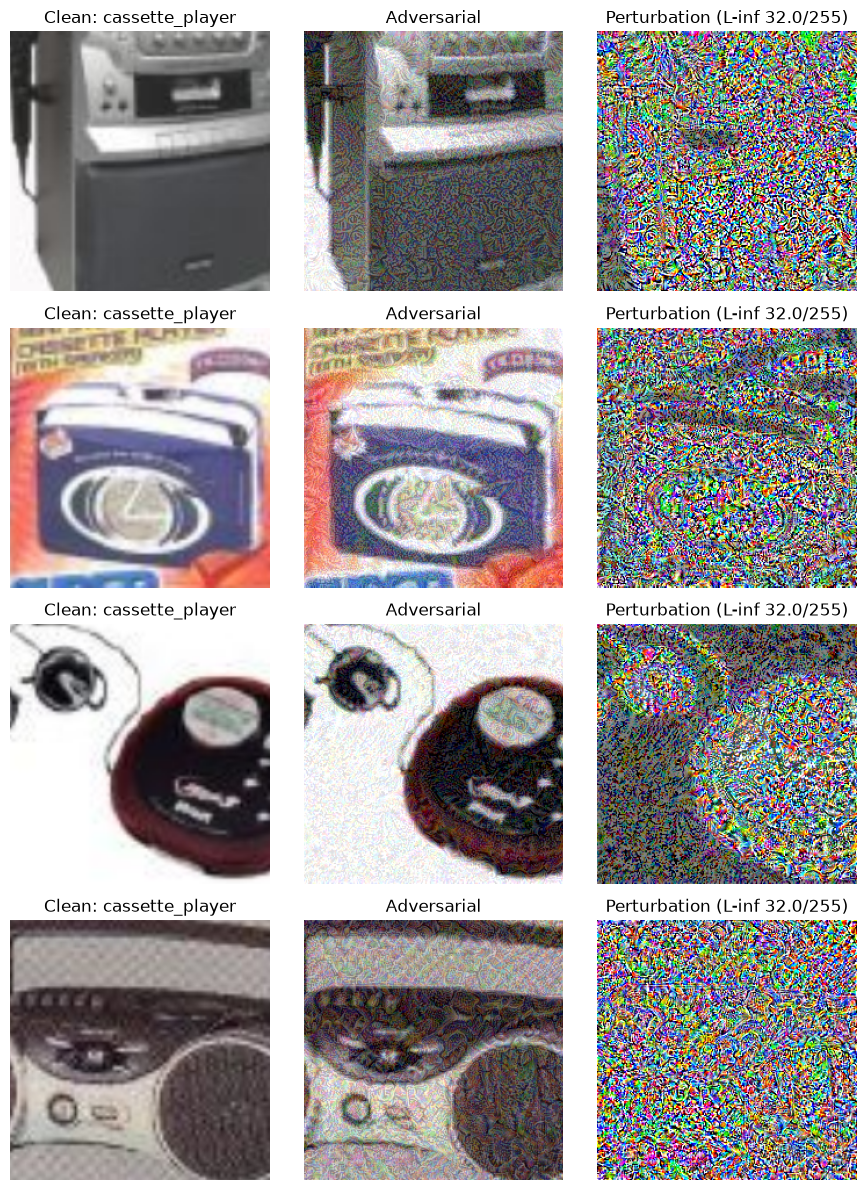

In [10]:
n_show = min(4, len(meta))
fig, axes = plt.subplots(n_show, 3, figsize=(9, 3 * n_show))
axes = np.atleast_2d(axes)

for r in range(n_show):
    row = meta.iloc[r]
    clean = preprocess(Image.open(row["source_path"]).convert("RGB"))          # same preprocessing as the attack
    adv = T.ToTensor()(Image.open(os.path.join(OUT_DIR, row["file"])).convert("RGB"))
    diff = adv - clean
    diff_vis = (diff / (2 * eps) + 0.5).clamp(0, 1)                             # map [-eps, eps] -> [0, 1]

    axes[r, 0].imshow(clean.permute(1, 2, 0).numpy());    axes[r, 0].set_title(f"Clean: {row['class']}")
    axes[r, 1].imshow(adv.permute(1, 2, 0).numpy());      axes[r, 1].set_title("Adversarial")
    axes[r, 2].imshow(diff_vis.permute(1, 2, 0).numpy()); axes[r, 2].set_title(f"Perturbation (L-inf {row['linf_255']}/255)")
    for a in axes[r]:
        a.axis("off")

plt.tight_layout()
plt.show()

## 8. Using the dataset in your other experiment

The output folder is in standard `ImageFolder` layout, so it loads directly. Copy the snippet below into your other project.

**Important details:**
- Load with a plain `ToTensor()`. **Do not resize, crop, or re-compress** the images: they are already 224x224 and any resampling or JPEG compression weakens the perturbation.
- `ImageFolder` assigns labels alphabetically by folder name. Our folder names are chosen so this reproduces Imagenette's standard label order (`tench`=0, `english_springer`=1, ... `parachute`=9), but note this is the 0-9 Imagenette label, **not** the ImageNet-1k index. If you evaluate a 1000-class ImageNet model, map with `IMAGENETTE_TO_IN1K[label]`.
- If you feed the images to a model that expects normalisation, apply ImageNet mean/std *after* `ToTensor()` (our attack handled this inside the model wrappers).
- `metadata.csv` lets you pair each adversarial image with its original clean image via `source_path`.

In [ ]:
# ---- Copy-paste snippet for your separate experiment ----
from torchvision.datasets import ImageFolder
import torchvision.transforms as T
from torch.utils.data import DataLoader

adv_dataset = ImageFolder(OUT_DIR, transform=T.ToTensor())      # no resize / crop / jitter!
adv_loader = DataLoader(adv_dataset, batch_size=64, shuffle=False)

print(adv_dataset.classes)          # alphabetical == Imagenette order
print(len(adv_dataset), "adversarial images")

# Example: map Imagenette labels (0-9) to ImageNet-1k indices for a 1000-class model
# imagenet_labels = torch.tensor(IMAGENETTE_TO_IN1K)[labels]